In [2]:
import json
import math
import random
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Tuple
import itertools

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from torch.utils.data import DataLoader, TensorDataset

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

OUTPUT_DIR = "notebook_outputs"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Output dir:", OUTPUT_DIR)


Device: cuda
Output dir: notebook_outputs


In [3]:
train = pd.read_csv("train.csv", parse_dates=["datetime"]).sort_values("datetime").reset_index(drop=True)
test = pd.read_csv("test.csv", parse_dates=["datetime"]).sort_values("datetime").reset_index(drop=True)

print("train shape:", train.shape)
print("test shape:", test.shape)
display(train.head())
display(test.head())

print("Missing values in train:")
display(train.isna().sum().to_frame("missing_count"))
print("Missing values in test:")
display(test.isna().sum().to_frame("missing_count"))


train shape: (10886, 12)
test shape: (6493, 9)


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed
0,2011-01-20 00:00:00,1,0,1,1,10.66,11.365,56,26.0027
1,2011-01-20 01:00:00,1,0,1,1,10.66,13.635,56,0.0000
2,2011-01-20 02:00:00,1,0,1,1,10.66,13.635,56,0.0000
3,2011-01-20 03:00:00,1,0,1,1,10.66,12.880,56,11.0014
4,2011-01-20 04:00:00,1,0,1,1,10.66,12.880,56,11.0014


Missing values in train:


,missing_count
datetime,0
season,0
holiday,0
workingday,0
weather,0
temp,0
atemp,0
humidity,0
windspeed,0
casual,0


Missing values in test:


,missing_count
datetime,0
season,0
holiday,0
workingday,0
weather,0
temp,0
atemp,0
humidity,0
windspeed,0


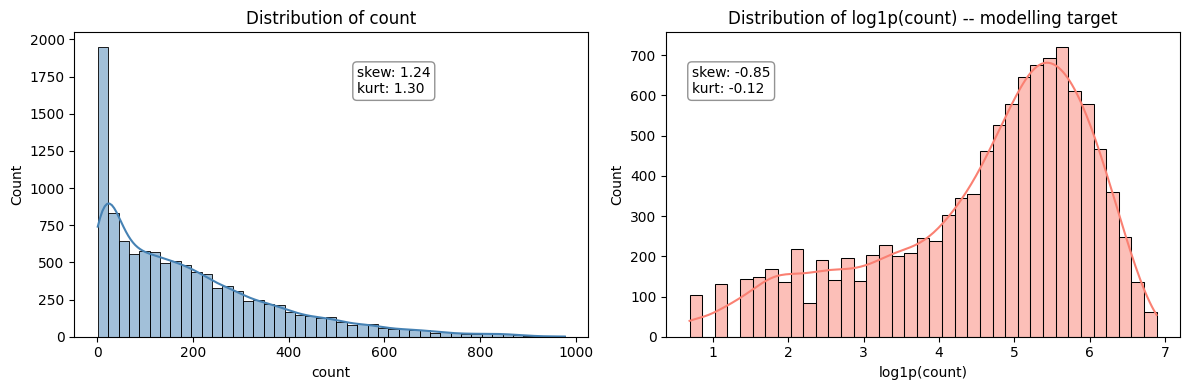

Skewness before log1p: 1.242, after: -0.851


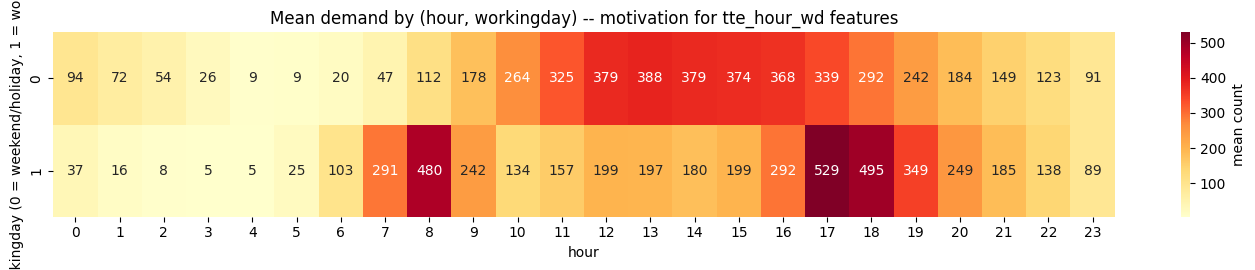

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import skew, kurtosis

# ---- Target distribution before/after log1p ----
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train["count"], kde=True, color="steelblue", ax=axes[0])
axes[0].set_title("Distribution of count")
axes[0].set_xlabel("count")
s = skew(train["count"]); k = kurtosis(train["count"])
axes[0].text(0.55, 0.80, f"skew: {s:.2f}\nkurt: {k:.2f}",
             transform=axes[0].transAxes,
             bbox=dict(boxstyle="round", fc="white", ec="gray", alpha=0.85))

sns.histplot(np.log1p(train["count"]), kde=True, color="salmon", ax=axes[1])
axes[1].set_title("Distribution of log1p(count) -- modelling target")
axes[1].set_xlabel("log1p(count)")
s2 = skew(np.log1p(train["count"])); k2 = kurtosis(np.log1p(train["count"]))
axes[1].text(0.05, 0.80, f"skew: {s2:.2f}\nkurt: {k2:.2f}",
             transform=axes[1].transAxes,
             bbox=dict(boxstyle="round", fc="white", ec="gray", alpha=0.85))
plt.tight_layout(); plt.show()
print(f"Skewness before log1p: {s:.3f}, after: {s2:.3f}")

# ---- Hour x Workingday demand heatmap ----
# Motivating figure for our TemporalTargetFeatures addition: demand has a
# strong hour x workingday interaction that tree models learn via splits
# but that a plain MLP struggles to learn from cyclical/one-hot encodings
# alone.
eda_tmp = train.copy()
eda_tmp["hour"] = eda_tmp["datetime"].dt.hour
hw_pivot = eda_tmp.pivot_table(index="workingday", columns="hour",
                               values="count", aggfunc="mean")

plt.figure(figsize=(14, 2.8))
sns.heatmap(hw_pivot, cmap="YlOrRd", annot=True, fmt=".0f",
            cbar_kws={"label": "mean count"})
plt.title("Mean demand by (hour, workingday) -- motivation for tte_hour_wd features")
plt.ylabel("workingday (0 = weekend/holiday, 1 = workday)")
plt.tight_layout(); plt.show()


## Step 1. Treat `windspeed == 0` as missing and impute it

In [6]:
def add_basic_time_features(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["year"] = out["datetime"].dt.year
    out["month"] = out["datetime"].dt.month
    out["day"] = out["datetime"].dt.day
    out["hour"] = out["datetime"].dt.hour
    out["weekday"] = out["datetime"].dt.weekday
    return out


def fit_windspeed_imputer(reference_df: pd.DataFrame) -> RandomForestRegressor:
    ref = add_basic_time_features(reference_df)
    feature_cols = [
        "season", "holiday", "workingday", "weather", "temp", "atemp", "humidity",
        "year", "month", "day", "hour", "weekday"
    ]
    known_mask = ref["windspeed"] > 0
    rf = RandomForestRegressor(
        n_estimators=300,
        max_depth=18,
        min_samples_leaf=2,
        random_state=RANDOM_SEED,
        n_jobs=1,
    )
    rf.fit(ref.loc[known_mask, feature_cols], ref.loc[known_mask, "windspeed"])
    return rf


def apply_windspeed_imputer(df: pd.DataFrame, rf: RandomForestRegressor) -> pd.DataFrame:
    out = add_basic_time_features(df)
    feature_cols = [
        "season", "holiday", "workingday", "weather", "temp", "atemp", "humidity",
        "year", "month", "day", "hour", "weekday"
    ]
    unknown_mask = out["windspeed"] == 0
    if unknown_mask.any():
        out.loc[unknown_mask, "windspeed"] = rf.predict(out.loc[unknown_mask, feature_cols])
    return out[df.columns].reset_index(drop=True)


print("train windspeed == 0 count:", (train["windspeed"] == 0).sum())
print("test windspeed == 0 count:", (test["windspeed"] == 0).sum())

train_raw = train.copy()
test_raw = test.copy()


train windspeed == 0 count: 1313
test windspeed == 0 count: 867


## Step 2. Feature Engineering

We split features into three groups:

1. **Calendar & cyclical features** (`add_features`): year/month/hour/weekday plus
   sine/cosine encodings, weekend/peak/commute flags, and a `days_since_2011`
   trend column.
2. **Weather interaction features**: `temp_diff`, `humidity_wind`, `feels_hot/cold`.
3. **Temporal target-encoded features** (`TemporalTargetFeatures`, new):
   historical aggregates of `log1p(count)` grouped by
   `(hour, workingday)`, `(hour, weekday)`, `(hour, season)`, `(hour, month)`,
   and `(year, month)`. These are fit on the TRAINING target only and looked
   up by calendar keys at prediction time, so they are safe across the
   train/test gap (train = day 1–19 of each month, test = day 20–end).

   Why: the original ANN had no way to learn "typical demand at 8am on a
   working day" other than memorising raw (hour, workingday) interactions
   through its weights. Tree models learn this implicitly via splits and
   LSTM learns it from the sequence context. Providing these aggregates
   explicitly closes the gap for the MLP without introducing leakage or
   breaking the Kaggle evaluation protocol.


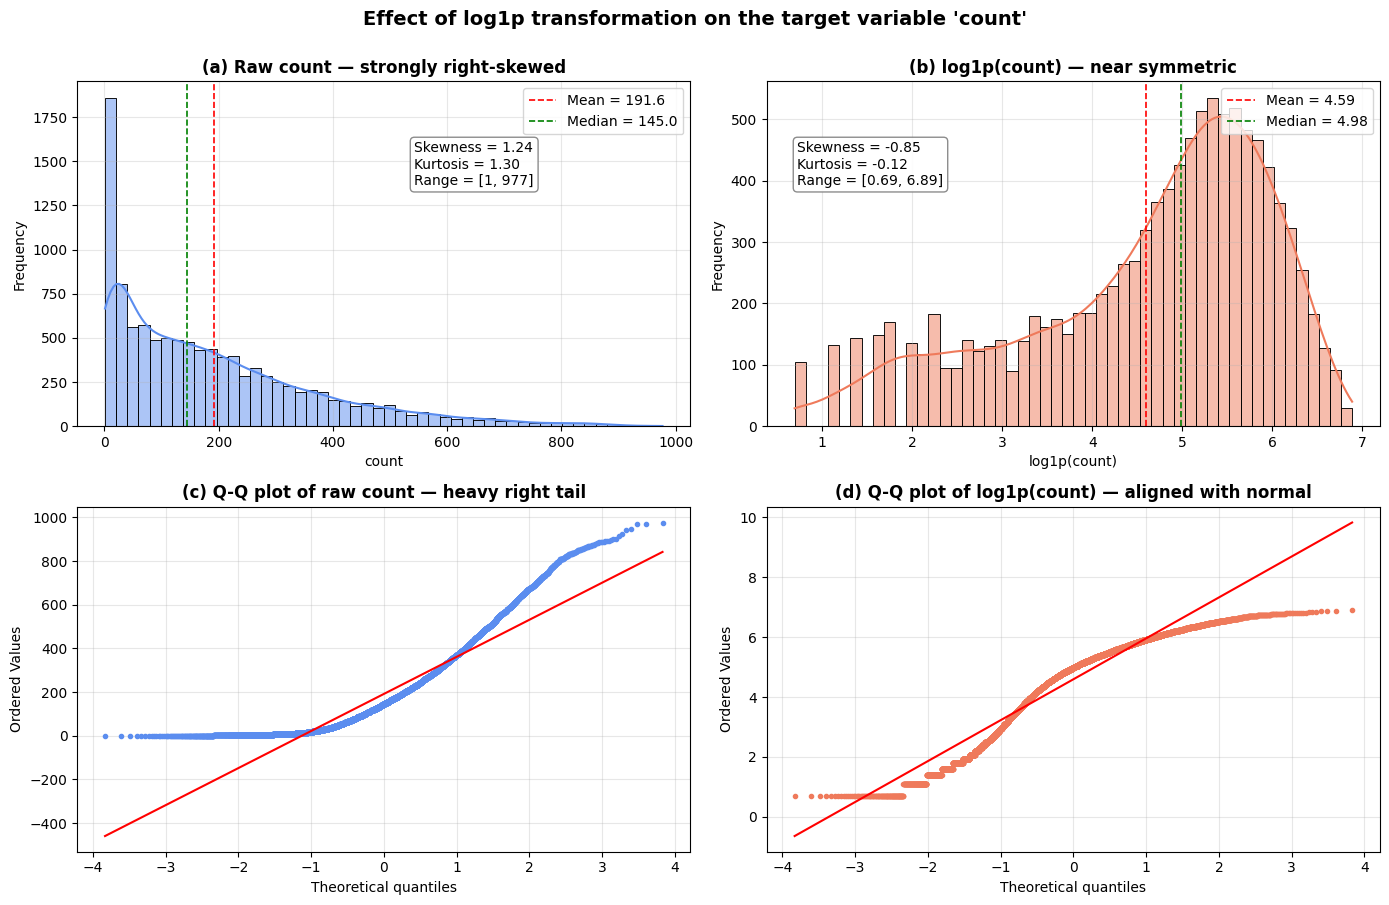

Target variable transformation summary
Metric                     Raw count    log1p(count)
------------------------------------------------------------
Skewness                       1.242          -0.851
Kurtosis                       1.299          -0.120
Mean                          191.57           4.591
Std                           181.14           1.419
Median                        145.00           4.984
Max                              977           6.886
------------------------------------------------------------
Skewness reduction: 31.5%


In [7]:
# ========== 用于报告 Section 2.3 的可视化：log1p 变换效果对比 ==========
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import skew, kurtosis

# 确保 train 已经加载
# train = pd.read_csv("train.csv", parse_dates=["datetime"])

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# ---- 左上：原始 count 直方图 + KDE ----
raw = train["count"].values
s_raw = skew(raw); k_raw = kurtosis(raw)
sns.histplot(raw, kde=True, color="#5B8DEF", bins=50, ax=axes[0, 0])
axes[0, 0].axvline(np.mean(raw), color="red", linestyle="--", linewidth=1.2, label=f"Mean = {np.mean(raw):.1f}")
axes[0, 0].axvline(np.median(raw), color="green", linestyle="--", linewidth=1.2, label=f"Median = {np.median(raw):.1f}")
axes[0, 0].set_title("(a) Raw count — strongly right-skewed", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("count"); axes[0, 0].set_ylabel("Frequency")
axes[0, 0].text(0.55, 0.70,
                f"Skewness = {s_raw:.2f}\nKurtosis = {k_raw:.2f}\nRange = [{raw.min()}, {raw.max()}]",
                transform=axes[0, 0].transAxes,
                bbox=dict(boxstyle="round", fc="white", ec="gray", alpha=0.9), fontsize=10)
axes[0, 0].legend(loc="upper right")
axes[0, 0].grid(alpha=0.3)

# ---- 右上：log1p(count) 直方图 + KDE ----
log_count = np.log1p(raw)
s_log = skew(log_count); k_log = kurtosis(log_count)
sns.histplot(log_count, kde=True, color="#EF7A5B", bins=50, ax=axes[0, 1])
axes[0, 1].axvline(np.mean(log_count), color="red", linestyle="--", linewidth=1.2, label=f"Mean = {np.mean(log_count):.2f}")
axes[0, 1].axvline(np.median(log_count), color="green", linestyle="--", linewidth=1.2, label=f"Median = {np.median(log_count):.2f}")
axes[0, 1].set_title("(b) log1p(count) — near symmetric", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("log1p(count)"); axes[0, 1].set_ylabel("Frequency")
axes[0, 1].text(0.05, 0.70,
                f"Skewness = {s_log:.2f}\nKurtosis = {k_log:.2f}\nRange = [{log_count.min():.2f}, {log_count.max():.2f}]",
                transform=axes[0, 1].transAxes,
                bbox=dict(boxstyle="round", fc="white", ec="gray", alpha=0.9), fontsize=10)
axes[0, 1].legend(loc="upper right")
axes[0, 1].grid(alpha=0.3)

# ---- 左下：原始 count 的 Q-Q plot（偏离正态）----
stats.probplot(raw, dist="norm", plot=axes[1, 0])
axes[1, 0].set_title("(c) Q-Q plot of raw count — heavy right tail", fontsize=12, fontweight="bold")
axes[1, 0].get_lines()[0].set_markerfacecolor("#5B8DEF")
axes[1, 0].get_lines()[0].set_markeredgecolor("#5B8DEF")
axes[1, 0].get_lines()[0].set_markersize(3)
axes[1, 0].get_lines()[1].set_color("red")
axes[1, 0].grid(alpha=0.3)

# ---- 右下：log1p(count) 的 Q-Q plot（接近正态）----
stats.probplot(log_count, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("(d) Q-Q plot of log1p(count) — aligned with normal", fontsize=12, fontweight="bold")
axes[1, 1].get_lines()[0].set_markerfacecolor("#EF7A5B")
axes[1, 1].get_lines()[0].set_markeredgecolor("#EF7A5B")
axes[1, 1].get_lines()[0].set_markersize(3)
axes[1, 1].get_lines()[1].set_color("red")
axes[1, 1].grid(alpha=0.3)

plt.suptitle("Effect of log1p transformation on the target variable 'count'",
             fontsize=14, fontweight="bold", y=1.00)
plt.tight_layout()
plt.savefig("log_transform_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- 文字输出，用于报告 ----
print("=" * 60)
print("Target variable transformation summary")
print("=" * 60)
print(f"{'Metric':<20} {'Raw count':>15} {'log1p(count)':>15}")
print("-" * 60)
print(f"{'Skewness':<20} {s_raw:>15.3f} {s_log:>15.3f}")
print(f"{'Kurtosis':<20} {k_raw:>15.3f} {k_log:>15.3f}")
print(f"{'Mean':<20} {np.mean(raw):>15.2f} {np.mean(log_count):>15.3f}")
print(f"{'Std':<20} {np.std(raw):>15.2f} {np.std(log_count):>15.3f}")
print(f"{'Median':<20} {np.median(raw):>15.2f} {np.median(log_count):>15.3f}")
print(f"{'Max':<20} {raw.max():>15.0f} {log_count.max():>15.3f}")
print("-" * 60)
print(f"Skewness reduction: {(abs(s_raw) - abs(s_log)) / abs(s_raw) * 100:.1f}%")

In [8]:
def add_features(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    dt = out["datetime"]
    out["year"] = dt.dt.year
    out["month"] = dt.dt.month
    out["day"] = dt.dt.day
    out["hour"] = dt.dt.hour
    out["weekday"] = dt.dt.weekday
    out["weekofyear"] = dt.dt.isocalendar().week.astype(int)
    out["dayofyear"] = dt.dt.dayofyear
    out["quarter"] = dt.dt.quarter
    out["is_weekend"] = (out["weekday"] >= 5).astype(int)
    out["is_peak"] = out["hour"].isin([7, 8, 9, 17, 18, 19]).astype(int)
    out["is_commute_window"] = ((out["workingday"] == 1) & out["hour"].isin([7, 8, 9, 17, 18, 19])).astype(int)

    out["hour_sin"] = np.sin(2 * np.pi * out["hour"] / 24)
    out["hour_cos"] = np.cos(2 * np.pi * out["hour"] / 24)
    out["weekday_sin"] = np.sin(2 * np.pi * out["weekday"] / 7)
    out["weekday_cos"] = np.cos(2 * np.pi * out["weekday"] / 7)
    out["month_sin"] = np.sin(2 * np.pi * out["month"] / 12)
    out["month_cos"] = np.cos(2 * np.pi * out["month"] / 12)

    out["temp_diff"] = out["atemp"] - out["temp"]
    out["humidity_wind"] = out["humidity"] * out["windspeed"]
    out["feels_hot"] = ((out["temp"] >= 28) & (out["humidity"] >= 70)).astype(int)
    out["feels_cold"] = ((out["temp"] <= 10) & (out["windspeed"] >= 15)).astype(int)

    # ---- Monotonic trend feature (safe at test time) ----
    # System-wide growth from 2011 -> 2012. Lets a plain MLP see the upward trend
    # that tree models pick up implicitly via the `year` split.
    out["days_since_2011"] = (dt - pd.Timestamp("2011-01-01")).dt.total_seconds() / 86400.0
    return out


# -------------------------------------------------------------
# NEW: temporal target-encoded features
# -------------------------------------------------------------
# Rationale:
#   The MLP (ANN) only sees point-in-time features and has no mechanism to learn
#   "what the typical demand level is for this (hour, workingday) combination".
#   Tree models learn this implicitly via splits; LSTM learns it via sequence
#   context. To give the ANN comparable information WITHOUT breaking the
#   Kaggle train/test structure (train = day 1-19, test = day 20-end, so
#   standard count.shift(1) lags are unavailable at test time), we build
#   *historical aggregate* features using ONLY the training target:
#
#     - count_by_hour_workingday_{mean, median}
#     - count_by_hour_weekday_mean
#     - count_by_season_hour_mean
#     - count_by_month_hour_mean            (captures year/season trend per hour)
#     - count_by_year_month_mean            (captures the global upward trend)
#
#   These are safe because they depend only on training-set aggregates and are
#   looked up by calendar keys available in both train and test.
#
#   All statistics are fit on the TRAINING target only (inside sklearn Pipeline
#   via the `y` passed to .fit). No leakage into the validation / test set.
# -------------------------------------------------------------
class TemporalTargetFeatures(BaseEstimator, TransformerMixin):
    """Adds historical groupby-mean features of the target.

    Fit on training (X, y) only; transform uses stored lookup tables.
    Expects X to already contain engineered calendar columns
    (hour, weekday, workingday, season, month, year) -- i.e. it is placed
    AFTER BikeFeatureEngineer in the pipeline... but BikeFeatureEngineer
    drops the datetime column, so instead we derive calendar keys here
    from the original datetime. To keep the pipeline simple, this
    transformer operates on the RAW dataframe (with `datetime`) and is
    therefore inserted BEFORE BikeFeatureEngineer. It only adds numeric
    columns; downstream feature engineering is untouched.
    """

    GROUPS = [
        ("tte_hour_wd", ["hour", "workingday"]),
        ("tte_hour_weekday", ["hour", "weekday"]),
        ("tte_hour_season", ["hour", "season"]),
        ("tte_hour_month", ["hour", "month"]),
        ("tte_year_month", ["year", "month"]),
    ]

    def __init__(self, target_log: bool = True):
        self.target_log = target_log

    def _key_frame(self, X: pd.DataFrame) -> pd.DataFrame:
        dt = X["datetime"]
        return pd.DataFrame({
            "hour": dt.dt.hour,
            "weekday": dt.dt.weekday,
            "workingday": X["workingday"].values,
            "season": X["season"].values,
            "month": dt.dt.month,
            "year": dt.dt.year,
        })

    def fit(self, X: pd.DataFrame, y=None):
        if y is None:
            raise ValueError("TemporalTargetFeatures requires y at fit time.")
        keys = self._key_frame(X)
        # y here is already log1p(count) in our pipeline, which is the
        # natural space for aggregation (reduces skew influence).
        y_arr = np.asarray(y).astype(float)
        self.global_mean_ = float(np.mean(y_arr))
        self.lookups_ = {}
        df = keys.copy()
        df["_y"] = y_arr
        for name, cols in self.GROUPS:
            grp = df.groupby(cols)["_y"]
            self.lookups_[name] = pd.DataFrame({
                f"{name}_mean": grp.mean(),
                f"{name}_median": grp.median(),
            }).reset_index()
        return self

    def transform(self, X: pd.DataFrame) -> pd.DataFrame:
        out = X.copy().reset_index(drop=True)
        keys = self._key_frame(out)
        for name, cols in self.GROUPS:
            lut = self.lookups_[name]
            merged = keys[cols].merge(lut, on=cols, how="left")
            for c in [f"{name}_mean", f"{name}_median"]:
                if c in merged.columns:
                    vals = merged[c].fillna(self.global_mean_).to_numpy()
                    out[c] = vals
        return out


# List of new columns produced by TemporalTargetFeatures
temporal_target_cols = []
for name, _ in TemporalTargetFeatures.GROUPS:
    temporal_target_cols.extend([f"{name}_mean", f"{name}_median"])

_drop_cols = ["datetime", "count", "casual", "registered"]
# Build an example through the temporal + feature engineer stack so the new
# columns are included in feature_cols.
_tmp = train_raw.iloc[:2].copy()
_tmp_y = np.log1p(_tmp["count"].to_numpy()) if "count" in _tmp.columns else np.zeros(len(_tmp))
_tte = TemporalTargetFeatures().fit(_tmp, _tmp_y).transform(_tmp)
_example = add_features(_tte)
feature_cols = [c for c in _example.columns if c not in _drop_cols]

categorical_cols = ["season", "weather", "month", "weekday", "quarter", "year"]
numeric_cols = [c for c in feature_cols if c not in categorical_cols]


class WindspeedZeroImputer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.rf_ = fit_windspeed_imputer(X.copy())
        return self

    def transform(self, X):
        return apply_windspeed_imputer(X.copy(), self.rf_)


class BikeFeatureEngineer(BaseEstimator, TransformerMixin):
    """Drops raw datetime, keeps engineered columns + upstream temporal target cols."""

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        fe = add_features(X.copy())
        # Keep only known feature_cols (which already includes temporal_target_cols
        # because _example above was built through TemporalTargetFeatures).
        keep = [c for c in feature_cols if c in fe.columns]
        missing = [c for c in feature_cols if c not in fe.columns]
        if missing:
            # Temporal cols come from upstream TemporalTargetFeatures; if this
            # transformer is used standalone (e.g. for LSTM), fill with 0 so
            # shape stays consistent. For LSTM we will use a separate feature_cols.
            for c in missing:
                fe[c] = 0.0
        return fe[feature_cols]


print("feature count:", len(feature_cols))
print("categorical cols:", categorical_cols)
print("numeric feature count:", len(numeric_cols))
print("new temporal target cols:", temporal_target_cols)


feature count: 40
categorical cols: ['season', 'weather', 'month', 'weekday', 'quarter', 'year']
numeric feature count: 34
new temporal target cols: ['tte_hour_wd_mean', 'tte_hour_wd_median', 'tte_hour_weekday_mean', 'tte_hour_weekday_median', 'tte_hour_season_mean', 'tte_hour_season_median', 'tte_hour_month_mean', 'tte_hour_month_median', 'tte_year_month_mean', 'tte_year_month_median']


## Step 3. Time-based Train/Validation Split

In [9]:
split_idx = int(len(train_raw) * 0.8)

train_outer_raw = train_raw.iloc[:split_idx].reset_index(drop=True)
val_outer_raw = train_raw.iloc[split_idx:].reset_index(drop=True)
all_train_raw = train_raw.reset_index(drop=True)

X_train_raw = train_outer_raw.drop(columns=["count", "casual", "registered"])
y_train = train_outer_raw["count"].reset_index(drop=True)
X_val_raw = val_outer_raw.drop(columns=["count", "casual", "registered"])
y_val = val_outer_raw["count"].reset_index(drop=True)
X_all_raw = all_train_raw.drop(columns=["count", "casual", "registered"])
y_all = all_train_raw["count"].reset_index(drop=True)
X_test_raw = test_raw.copy().reset_index(drop=True)

print("Train range:", train_outer_raw.iloc[0]["datetime"], "to", train_outer_raw.iloc[len(train_outer_raw) - 1]["datetime"])
print("Val range:", val_outer_raw.iloc[0]["datetime"], "to", val_outer_raw.iloc[len(val_outer_raw) - 1]["datetime"])
print("X_train_raw:", X_train_raw.shape, "X_val_raw:", X_val_raw.shape)


Train range: 2011-01-01 00:00:00 to 2012-08-05 04:00:00
Val range: 2012-08-05 05:00:00 to 2012-12-19 23:00:00
X_train_raw: (8708, 9) X_val_raw: (2178, 9)


In [10]:
def compute_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> Dict[str, float]:
    mse = mean_squared_error(y_true, y_pred)
    return {
        "RMSE": float(np.sqrt(mse)),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "R2": float(r2_score(y_true, y_pred)),
        "MAPE": float(mean_absolute_percentage_error(y_true, y_pred)),
    }


def clipped_inverse(pred_log: np.ndarray) -> np.ndarray:
    return np.clip(np.expm1(pred_log), 0, None)


def make_preprocessor() -> ColumnTransformer:
    return ColumnTransformer(
        transformers=[
            (
                "num",
                Pipeline([
                    ("scaler", StandardScaler()),
                ]),
                numeric_cols,
            ),
            (
                "cat",
                OneHotEncoder(handle_unknown="ignore"),
                categorical_cols,
            ),
        ]
    )


y_train_log = np.log1p(y_train.to_numpy())
y_all_log = np.log1p(y_all.to_numpy())


## Step 4. Baseline Models and Hyperparameter Tuning

In [11]:
results = []
trained_models = {}

# NOTE: TemporalTargetFeatures must be BEFORE BikeFeatureEngineer,
# because it consumes the raw `datetime` column and needs y at fit time.
# sklearn Pipeline forwards y to every transformer's fit(), so the
# training target (log1p count) is used to build the aggregate lookups.
base_steps = [
    ("windspeed_imputer", WindspeedZeroImputer()),
    ("temporal_target", TemporalTargetFeatures()),
    ("feature_engineer", BikeFeatureEngineer()),
    ("preprocessor", make_preprocessor()),
]

# 1) Linear Regression
linear_model = Pipeline(base_steps + [
    ("model", LinearRegression()),
])
linear_model.fit(X_train_raw, y_train_log)
linear_val_pred = clipped_inverse(linear_model.predict(X_val_raw))
linear_metrics = compute_metrics(y_val.to_numpy(), linear_val_pred)
results.append({"model": "LinearRegression", **linear_metrics, "best_params": {}})
trained_models["LinearRegression"] = linear_model
print("LinearRegression done:", linear_metrics)

# 2) Random Forest with tuning
rf_pipeline = Pipeline(base_steps + [
    ("model", RandomForestRegressor(random_state=RANDOM_SEED, n_jobs=1)),
])
rf_param_dist = {
    "model__n_estimators": [150, 250, 350],
    "model__max_depth": [12, 18, 24, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", 0.7, 0.9],
}
rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_param_dist,
    n_iter=6,
    scoring="neg_root_mean_squared_error",
    cv=TimeSeriesSplit(n_splits=3),
    random_state=RANDOM_SEED,
    n_jobs=1,
    verbose=1,
)
rf_search.fit(X_train_raw, y_train_log)
rf_best = rf_search.best_estimator_
rf_val_pred = clipped_inverse(rf_best.predict(X_val_raw))
rf_metrics = compute_metrics(y_val.to_numpy(), rf_val_pred)
results.append({"model": "RandomForest", **rf_metrics, "best_params": rf_search.best_params_})
trained_models["RandomForest"] = rf_best
print("RandomForest best params:", rf_search.best_params_)
print("RandomForest metrics:", rf_metrics)


# 3) ANN (PyTorch MLP) -- training protocol intentionally mirrors the LSTM:
#      * log1p(count) + StandardScaler on the target
#      * TIME-ORDERED inner validation split for early stopping
#      * manual patience-based early stopping + best-state restore
#      * identical feature pipeline (incl. TemporalTargetFeatures) applied
#        consistently across train / inner-val / outer-val
#
#    Why not sklearn's MLPRegressor(early_stopping=True)?
#    -- it uses a RANDOMLY SHUFFLED internal val split, which leaks
#       same-day samples into the stopping criterion for time-series data.
#       Rewriting in PyTorch lets us apply the same time-ordered discipline
#       as the LSTM and keeps the ANN vs LSTM comparison apples-to-apples.

class BikeDemandMLP(nn.Module):
    def __init__(self, input_dim: int, hidden_dims=(128, 64), dropout: float = 0.1):
        super().__init__()
        layers = []
        prev = input_dim
        for h in hidden_dims:
            layers.append(nn.Linear(prev, h))
            layers.append(nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x).squeeze(-1)


def _fit_ann_feature_pipeline(X_fit_raw, y_fit_log):
    """Fit windspeed imputer + TTE + feature engineer + preprocessor on fit data only.

    Returns the fitted pipeline so it can be applied to validation / test data
    without leakage. TTE uses y_fit_log; preprocessor (StandardScaler + OneHot)
    uses the transformed feature matrix.
    """
    feat_pipeline = Pipeline([
        ("windspeed_imputer", WindspeedZeroImputer()),
        ("temporal_target", TemporalTargetFeatures()),
        ("feature_engineer", BikeFeatureEngineer()),
        ("preprocessor", make_preprocessor()),
    ])
    feat_pipeline.fit(X_fit_raw, y_fit_log)
    return feat_pipeline


def train_ann_once(
    X_tr_raw, y_tr_log, X_va_raw, y_va_log,
    hidden_dims, dropout, lr, batch_size, weight_decay,
    max_epochs=200, patience=15, device=device,
):
    """Train one MLP with time-ordered early stopping on (X_va_raw, y_va_log).

    The feature pipeline is fit on TRAIN ONLY; validation data is only transformed.
    Target is further StandardScaler-normalised (fit on train log-count) to match
    the LSTM protocol.
    """
    feat_pipeline = _fit_ann_feature_pipeline(X_tr_raw, y_tr_log)
    X_tr = np.asarray(feat_pipeline.transform(X_tr_raw), dtype=np.float32)
    X_va = np.asarray(feat_pipeline.transform(X_va_raw), dtype=np.float32)

    target_scaler = StandardScaler()
    y_tr_s = target_scaler.fit_transform(y_tr_log.reshape(-1, 1)).ravel().astype(np.float32)
    y_va_s = target_scaler.transform(y_va_log.reshape(-1, 1)).ravel().astype(np.float32)

    model = BikeDemandMLP(input_dim=X_tr.shape[1], hidden_dims=hidden_dims, dropout=dropout).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.MSELoss()

    train_ds = TensorDataset(torch.tensor(X_tr), torch.tensor(y_tr_s))
    # shuffle=True is fine here: MLP is NOT a sequence model; we already kept
    # the time-ordered split between train/val, which is where the leakage
    # risk lives. Within a batch, order does not matter.
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)

    X_va_t = torch.tensor(X_va).to(device)
    y_va_t = torch.tensor(y_va_s).to(device)

    best_state, best_val, wait = None, float("inf"), 0
    train_losses, val_losses = [], []

    for epoch in range(max_epochs):
        model.train()
        batch_losses = []
        for bx, by in train_loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            loss = criterion(model(bx), by)
            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())

        model.eval()
        with torch.no_grad():
            v = criterion(model(X_va_t), y_va_t).item()
        train_losses.append(float(np.mean(batch_losses)))
        val_losses.append(float(v))

        if v < best_val:
            best_val = v
            best_state = {k: t.detach().cpu().clone() for k, t in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break

    model.load_state_dict(best_state)
    return {
        "model": model,
        "feat_pipeline": feat_pipeline,
        "target_scaler": target_scaler,
        "best_val_loss": best_val,
        "train_losses": train_losses,
        "val_losses": val_losses,
    }


def predict_ann(bundle, X_raw):
    X = np.asarray(bundle["feat_pipeline"].transform(X_raw), dtype=np.float32)
    bundle["model"].eval()
    with torch.no_grad():
        p_scaled = bundle["model"](torch.tensor(X).to(device)).cpu().numpy()
    p_log = bundle["target_scaler"].inverse_transform(p_scaled.reshape(-1, 1)).ravel()
    return clipped_inverse(p_log)


# -- Inner time-ordered split for hyperparameter search & early stopping --
ann_inner_split = int(len(X_train_raw) * 0.8)
X_ann_tune_tr = X_train_raw.iloc[:ann_inner_split].reset_index(drop=True)
y_ann_tune_tr_log = np.log1p(y_train.iloc[:ann_inner_split].to_numpy())
X_ann_tune_va = X_train_raw.iloc[ann_inner_split:].reset_index(drop=True)
y_ann_tune_va_log = np.log1p(y_train.iloc[ann_inner_split:].to_numpy())

ann_search_space = [
    {"hidden_dims": (128, 64),      "dropout": 0.1, "lr": 1e-3, "batch_size": 128, "weight_decay": 1e-5},
    {"hidden_dims": (128, 64),      "dropout": 0.2, "lr": 5e-4, "batch_size": 128, "weight_decay": 1e-4},
    {"hidden_dims": (128, 64, 32),  "dropout": 0.1, "lr": 1e-3, "batch_size": 128, "weight_decay": 1e-5},
    {"hidden_dims": (128, 64, 32),  "dropout": 0.2, "lr": 5e-4, "batch_size": 256, "weight_decay": 1e-4},
    {"hidden_dims": (256, 128, 64), "dropout": 0.2, "lr": 5e-4, "batch_size": 256, "weight_decay": 1e-4},
    {"hidden_dims": (256, 128, 64), "dropout": 0.3, "lr": 1e-3, "batch_size": 256, "weight_decay": 1e-3},
]

ann_tuning_records = []
best_ann_bundle = None
best_ann_params = None
best_ann_val = float("inf")

for params in ann_search_space:
    bundle = train_ann_once(
        X_ann_tune_tr, y_ann_tune_tr_log,
        X_ann_tune_va, y_ann_tune_va_log,
        max_epochs=200, patience=15,
        **params,
    )
    ann_tuning_records.append({**params, "best_val_loss": bundle["best_val_loss"]})
    print(params, "-> val_loss:", round(bundle["best_val_loss"], 5))
    if bundle["best_val_loss"] < best_ann_val:
        best_ann_val = bundle["best_val_loss"]
        best_ann_bundle = bundle
        best_ann_params = params

print("Best ANN params:", best_ann_params)
display(pd.DataFrame(ann_tuning_records).sort_values("best_val_loss"))

# -- Retrain best ANN on the full outer-train block; use trailing 10% (in time
#    order) as early-stopping val. Evaluate on outer val. --
retrain_split = int(len(X_train_raw) * 0.9)
X_ann_retr_tr = X_train_raw.iloc[:retrain_split].reset_index(drop=True)
y_ann_retr_tr_log = np.log1p(y_train.iloc[:retrain_split].to_numpy())
X_ann_retr_va = X_train_raw.iloc[retrain_split:].reset_index(drop=True)
y_ann_retr_va_log = np.log1p(y_train.iloc[retrain_split:].to_numpy())

ann_best_bundle = train_ann_once(
    X_ann_retr_tr, y_ann_retr_tr_log,
    X_ann_retr_va, y_ann_retr_va_log,
    max_epochs=300, patience=20,
    **best_ann_params,
)
ann_val_pred = predict_ann(ann_best_bundle, X_val_raw)
ann_metrics = compute_metrics(y_val.to_numpy(), ann_val_pred)
results.append({"model": "ANN", **ann_metrics, "best_params": best_ann_params})
trained_models["ANN"] = {
    "bundle": ann_best_bundle,
    "params": best_ann_params,
}
print("ANN metrics:", ann_metrics)


LinearRegression done: {'RMSE': 105.94205379764153, 'MAE': 70.5939529123343, 'R2': 0.762954649101447, 'MAPE': 0.2930076822441672}
Fitting 3 folds for each of 6 candidates, totalling 18 fits
RandomForest best params: {'model__n_estimators': 150, 'model__min_samples_split': 2, 'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': 12}
RandomForest metrics: {'RMSE': 105.25163327447417, 'MAE': 72.09416234146765, 'R2': 0.7660342135050762, 'MAPE': 0.2969390368875483}
{'hidden_dims': (128, 64), 'dropout': 0.1, 'lr': 0.001, 'batch_size': 128, 'weight_decay': 1e-05} -> val_loss: 0.05057
{'hidden_dims': (128, 64), 'dropout': 0.2, 'lr': 0.0005, 'batch_size': 128, 'weight_decay': 0.0001} -> val_loss: 0.0797
{'hidden_dims': (128, 64, 32), 'dropout': 0.1, 'lr': 0.001, 'batch_size': 128, 'weight_decay': 1e-05} -> val_loss: 0.05319
{'hidden_dims': (128, 64, 32), 'dropout': 0.2, 'lr': 0.0005, 'batch_size': 256, 'weight_decay': 0.0001} -> val_loss: 0.04754
{'hidden_dims': (256,

,hidden_dims,dropout,lr,batch_size,weight_decay,best_val_loss
3,"(128, 64, 32)",0.2,0.0005,256,0.00010,0.047542
0,"(128, 64)",0.1,0.0010,128,0.00001,0.050573
2,"(128, 64, 32)",0.1,0.0010,128,0.00001,0.053194
5,"(256, 128, 64)",0.3,0.0010,256,0.00100,0.065148
1,"(128, 64)",0.2,0.0005,128,0.00010,0.079701
4,"(256, 128, 64)",0.2,0.0005,256,0.00010,0.084901


ANN metrics: {'RMSE': 100.28040276987075, 'MAE': 67.05168151855469, 'R2': 0.787613570690155, 'MAPE': 0.27810385823249817}


## Step 5. LSTM Model and Tuning

In [12]:
# ============================================================
# 改进版 LSTM — 解决过拟合问题
# ============================================================
# 主要改动：
#   [1] Dropout 补偿：单层 LSTM 内部 dropout=0，改用 FC 前额外 Dropout 层
#   [2] 更强的 weight_decay：从 1e-5 提升到 1e-4 ~ 1e-3
#   [3] 学习率调度 (ReduceLROnPlateau)：验证loss停滞时自动降lr
#   [4] 更大的 patience (10~15)，避免过早停止
#   [5] 增加 L1 正则项选项（可选）
#   [6] 搜索空间更新：去掉过深配置，专注正则化强度的搜索
# ============================================================


class BikeDemandLSTM(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int = 64, num_layers: int = 2,
                 dropout: float = 0.2, bidirectional: bool = True,
                 use_attention: bool = True):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        self.bidirectional = bidirectional
        self.use_attention = use_attention

        lstm_dropout = dropout if num_layers > 1 else 0.0

        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=lstm_dropout,
            bidirectional=bidirectional,
        )
        out_dim = hidden_dim * (2 if bidirectional else 1)

        if use_attention:
            self.attn = nn.Linear(out_dim, 1)

        self.norm = nn.LayerNorm(out_dim)

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Sequential(
            nn.Linear(out_dim, out_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(out_dim // 2, 1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out, _ = self.lstm(x)                                  # (B, T, out_dim)
        if self.use_attention:
            attn_logits = self.attn(out).squeeze(-1)           # (B, T)
            attn_weights = torch.softmax(attn_logits, dim=1)
            pooled = torch.sum(out * attn_weights.unsqueeze(-1), dim=1)
        else:
            pooled = out[:, -1, :]

        pooled = self.norm(pooled)     # LayerNorm 先于 Dropout（更稳定）
        pooled = self.dropout(pooled)
        return self.fc(pooled).squeeze(-1)


@dataclass
class SequenceBundle:
    X_train: np.ndarray
    y_train: np.ndarray
    X_val: np.ndarray
    y_val: np.ndarray


def create_seq_bundle(features_scaled, targets_scaled, train_end_idx, val_end_idx, seq_len):
    X_train_seq, y_train_seq, X_val_seq, y_val_seq = [], [], [], []
    for target_idx in range(seq_len, val_end_idx):
        seq = features_scaled[target_idx - seq_len: target_idx]
        label = targets_scaled[target_idx]
        if target_idx < train_end_idx:
            X_train_seq.append(seq)
            y_train_seq.append(label)
        else:
            X_val_seq.append(seq)
            y_val_seq.append(label)
    return SequenceBundle(
        X_train=np.asarray(X_train_seq, dtype=np.float32),
        y_train=np.asarray(y_train_seq, dtype=np.float32),
        X_val=np.asarray(X_val_seq, dtype=np.float32),
        y_val=np.asarray(y_val_seq, dtype=np.float32),
    )


def train_lstm_once(bundle: SequenceBundle, params: Dict, device: torch.device):
    model = BikeDemandLSTM(
        input_dim=bundle.X_train.shape[2],
        hidden_dim=int(params["hidden_dim"]),
        num_layers=int(params["num_layers"]),
        dropout=float(params["dropout"]),
        bidirectional=bool(params.get("bidirectional", True)),
        use_attention=bool(params.get("use_attention", True)),
    ).to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=float(params["lr"]),
        weight_decay=float(params.get("weight_decay", 1e-4)),
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=5, min_lr=1e-6
    )

    criterion = nn.MSELoss()

    train_ds = TensorDataset(torch.tensor(bundle.X_train), torch.tensor(bundle.y_train))
    train_loader = DataLoader(train_ds, batch_size=int(params["batch_size"]), shuffle=False)

    X_val_t = torch.tensor(bundle.X_val).to(device)
    y_val_t = torch.tensor(bundle.y_val).to(device)

    best_state = None
    best_val_loss = float("inf")
    train_losses, val_losses = [], []
    wait = 0
    patience = int(params.get("patience", 12))   # [改动4] 默认 12

    for epoch in range(int(params["epochs"])):
        model.train()
        batch_losses = []
        for batch_X, batch_y in train_loader:
            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)
            optimizer.zero_grad()
            pred = model(batch_X)
            loss = criterion(pred, batch_y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            batch_losses.append(loss.item())

        model.eval()
        with torch.no_grad():
            val_loss = criterion(model(X_val_t), y_val_t).item()

        train_losses.append(float(np.mean(batch_losses)))
        val_losses.append(float(val_loss))

        scheduler.step(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print(f"  Early stopping at epoch {epoch + 1}, best_val={best_val_loss:.5f}")
                break

    model.load_state_dict(best_state)
    return model, best_val_loss, train_losses, val_losses


▶ seq=24 hid=64 L=1 drop=0.3 wd=1e-03 bi=1 attn=1
  Early stopping at epoch 32, best_val=0.15491
  val_loss=0.15491  final_train=0.16818  gap(train-val)=-0.11646

▶ seq=24 hid=64 L=2 drop=0.3 wd=1e-03 bi=1 attn=1
  Early stopping at epoch 43, best_val=0.11133
  val_loss=0.11133  final_train=0.10327  gap(train-val)=-0.03189

▶ seq=48 hid=64 L=2 drop=0.4 wd=1e-03 bi=1 attn=1
  Early stopping at epoch 59, best_val=0.10786
  val_loss=0.10786  final_train=0.12357  gap(train-val)=-0.13646

▶ seq=48 hid=128 L=2 drop=0.3 wd=1e-04 bi=1 attn=1
  Early stopping at epoch 55, best_val=0.12280
  val_loss=0.12280  final_train=0.09193  gap(train-val)=-0.06772

▶ seq=24 hid=128 L=2 drop=0.4 wd=1e-03 bi=1 attn=1
  Early stopping at epoch 77, best_val=0.11540
  val_loss=0.11540  final_train=0.10386  gap(train-val)=-0.08689

▶ seq=48 hid=64 L=2 drop=0.3 wd=1e-03 bi=1 attn=0
  Early stopping at epoch 37, best_val=0.06386
  val_loss=0.06386  final_train=0.07683  gap(train-val)=+0.00502

✅ Best LSTM params:

,seq_len,hidden_dim,num_layers,dropout,weight_decay,best_val_loss,final_train_loss,overfit_gap
5,48,64,2,0.3,0.0010,0.063864,0.076834,0.005020
2,48,64,2,0.4,0.0010,0.107861,0.123567,-0.136463
1,24,64,2,0.3,0.0010,0.111332,0.103273,-0.031885
4,24,128,2,0.4,0.0010,0.115395,0.103864,-0.086889
3,48,128,2,0.3,0.0001,0.122803,0.091928,-0.067718
0,24,64,1,0.3,0.0010,0.154908,0.168179,-0.116460


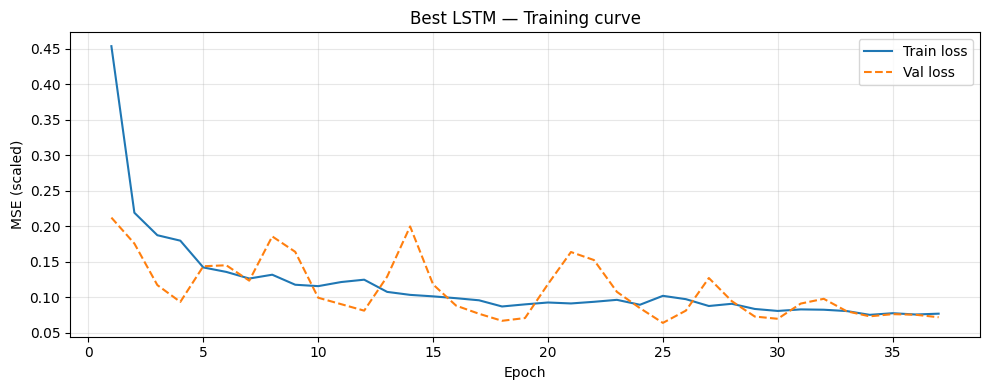

In [13]:
# ------------------------------------------------------------------
# LSTM training upgrades (summary of what's new vs the baseline version)
#
#   (1) Richer input features: TemporalTargetFeatures (tte_*) are now
#       included in the LSTM input channels as well. These historical
#       (hour, workingday) / (hour, season) / (year, month) aggregates
#       helped the ANN substantially; there is no reason to deny the
#       LSTM the same information. They are fit on the current TRAIN
#       slice only (no leakage into val).
#   (2) Architectural upgrades (see cell 13):
#         - Bidirectional LSTM (causally valid within the input window).
#         - Attention pooling over the time dimension.
#         - LayerNorm + dropout on pooled rep; gradient clipping.
#   (3) Optimisation upgrades:
#         - Weight decay (L2) for regularisation.
#         - Expanded hyperparameter search over seq_len / hidden_dim /
#           dropout / lr / weight_decay / bidirectional on/off /
#           attention on/off.
# ------------------------------------------------------------------

# Inner split within the outer training block (time-ordered)
inner_split_idx = int(len(X_train_raw) * 0.8)
X_tune_train_raw = X_train_raw.iloc[:inner_split_idx].reset_index(drop=True)
y_tune_train = y_train.iloc[:inner_split_idx].reset_index(drop=True)
X_tune_val_raw = X_train_raw.iloc[inner_split_idx:].reset_index(drop=True)
y_tune_val = y_train.iloc[inner_split_idx:].reset_index(drop=True)

# Windspeed imputation fit on inner train only
inner_windspeed_imputer = fit_windspeed_imputer(X_tune_train_raw)
X_tune_train_imputed = apply_windspeed_imputer(X_tune_train_raw, inner_windspeed_imputer)
X_tune_val_imputed = apply_windspeed_imputer(X_tune_val_raw, inner_windspeed_imputer)

# Temporal target features -- fit on inner train's log1p(count) only.
# This gives the LSTM the same (hour, workingday) historical aggregates
# the ANN uses, without leaking val-set targets.
inner_tte = TemporalTargetFeatures().fit(X_tune_train_imputed,
                                          np.log1p(y_tune_train.to_numpy()))
X_tune_train_tte = inner_tte.transform(X_tune_train_imputed)
X_tune_val_tte = inner_tte.transform(X_tune_val_imputed)

# LSTM now uses the full feature_cols (incl. tte_*). The preprocessor is
# the *general* make_preprocessor(), not the tte-free make_lstm_preprocessor().
X_tune_train_fe = add_features(X_tune_train_tte)[feature_cols]
X_tune_val_fe = add_features(X_tune_val_tte)[feature_cols]

lstm_preprocessor = make_preprocessor()
X_tune_train_scaled = np.asarray(lstm_preprocessor.fit_transform(X_tune_train_fe), dtype=np.float32)
X_tune_val_scaled = np.asarray(lstm_preprocessor.transform(X_tune_val_fe), dtype=np.float32)
X_tune_scaled = np.vstack([X_tune_train_scaled, X_tune_val_scaled])

# Target: log1p + StandardScaler (same as ANN, for consistency)
y_tune_train_log = np.log1p(y_tune_train.to_numpy())
y_tune_val_log = np.log1p(y_tune_val.to_numpy())
lstm_target_scaler = StandardScaler()
y_tune_train_scaled = lstm_target_scaler.fit_transform(y_tune_train_log.reshape(-1, 1)).ravel()
y_tune_val_scaled = lstm_target_scaler.transform(y_tune_val_log.reshape(-1, 1)).ravel()
y_tune_scaled = np.concatenate([y_tune_train_scaled, y_tune_val_scaled])


search_space = [
    {"seq_len": 24, "hidden_dim": 64,  "lr": 1e-3, "num_layers": 1, "dropout": 0.3,
     "batch_size": 128, "epochs": 100, "patience": 12, "weight_decay": 1e-3,
     "bidirectional": True, "use_attention": True},

    {"seq_len": 24, "hidden_dim": 64,  "lr": 5e-4, "num_layers": 2, "dropout": 0.3,
     "batch_size": 128, "epochs": 100, "patience": 12, "weight_decay": 1e-3,
     "bidirectional": True, "use_attention": True},

    {"seq_len": 48, "hidden_dim": 64,  "lr": 1e-3, "num_layers": 2, "dropout": 0.4,
     "batch_size": 128, "epochs": 100, "patience": 12, "weight_decay": 1e-3,
     "bidirectional": True, "use_attention": True},

    {"seq_len": 48, "hidden_dim": 128, "lr": 5e-4, "num_layers": 2, "dropout": 0.3,
     "batch_size": 128, "epochs": 100, "patience": 12, "weight_decay": 1e-4,
     "bidirectional": True, "use_attention": True},

    {"seq_len": 24, "hidden_dim": 128, "lr": 5e-4, "num_layers": 2, "dropout": 0.4,
     "batch_size": 256, "epochs": 100, "patience": 12, "weight_decay": 1e-3,
     "bidirectional": True, "use_attention": True},

    {"seq_len": 48, "hidden_dim": 64,  "lr": 5e-4, "num_layers": 2, "dropout": 0.3,
     "batch_size": 128, "epochs": 100, "patience": 12, "weight_decay": 1e-3,
     "bidirectional": True, "use_attention": False},
]


# ============================================================
# Training
# ============================================================

lstm_tuning_records = []
best_lstm_params = None
best_lstm_loss_curve = None
best_val_loss = float("inf")
best_state_global = None

for params in search_space:
    print(f"\n▶ seq={params['seq_len']} hid={params['hidden_dim']} "
          f"L={params['num_layers']} drop={params['dropout']} "
          f"wd={params['weight_decay']:.0e} "
          f"bi={int(params['bidirectional'])} attn={int(params['use_attention'])}")

    bundle = create_seq_bundle(
        features_scaled=X_tune_scaled,
        targets_scaled=y_tune_scaled,
        train_end_idx=len(X_tune_train_fe),
        val_end_idx=len(X_tune_scaled),
        seq_len=params["seq_len"],
    )
    model, val_loss, train_losses, val_losses = train_lstm_once(bundle, params, device)

    gap = train_losses[-1] - val_losses[-1] if val_losses else 0
    print(f"  val_loss={val_loss:.5f}  "
          f"final_train={train_losses[-1]:.5f}  "
          f"gap(train-val)={gap:+.5f}")

    record = {**params, "best_val_loss": float(val_loss),
              "final_train_loss": float(train_losses[-1]),
              "overfit_gap": float(gap)}
    lstm_tuning_records.append(record)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state_global = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        best_lstm_params = params
        best_lstm_loss_curve = {"train": train_losses, "val": val_losses}


final_model = BikeDemandLSTM(
    input_dim=X_tune_scaled.shape[1],
    hidden_dim=int(best_lstm_params["hidden_dim"]),
    num_layers=int(best_lstm_params["num_layers"]),
    dropout=float(best_lstm_params["dropout"]),
    bidirectional=bool(best_lstm_params["bidirectional"]),
    use_attention=bool(best_lstm_params["use_attention"]),
).to(device)
final_model.load_state_dict(best_state_global)

print("\n✅ Best LSTM params:", best_lstm_params)

results_df = pd.DataFrame(lstm_tuning_records).sort_values("best_val_loss")
display(results_df[["seq_len", "hidden_dim", "num_layers", "dropout", "weight_decay",
                     "best_val_loss", "final_train_loss", "overfit_gap"]])



fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(range(1, len(best_lstm_loss_curve["train"]) + 1),
        best_lstm_loss_curve["train"], label="Train loss", linewidth=1.5)
ax.plot(range(1, len(best_lstm_loss_curve["val"]) + 1),
        best_lstm_loss_curve["val"], label="Val loss", linewidth=1.5, linestyle="--")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE (scaled)")
ax.set_title("Best LSTM — Training curve")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [14]:
# Retrain best LSTM on the full outer-train block with TTE features
outer_windspeed_imputer = fit_windspeed_imputer(X_train_raw)
X_train_imputed_outer = apply_windspeed_imputer(X_train_raw, outer_windspeed_imputer)
X_val_imputed_outer = apply_windspeed_imputer(X_val_raw, outer_windspeed_imputer)

# TTE fit on outer train only
outer_tte = TemporalTargetFeatures().fit(X_train_imputed_outer,
                                          np.log1p(y_train.to_numpy()))
X_train_tte_outer = outer_tte.transform(X_train_imputed_outer)
X_val_tte_outer = outer_tte.transform(X_val_imputed_outer)

X_train_fe_outer = add_features(X_train_tte_outer)[feature_cols]
X_val_fe_outer = add_features(X_val_tte_outer)[feature_cols]

full_lstm_preprocessor = make_preprocessor()
X_train_scaled_outer = np.asarray(full_lstm_preprocessor.fit_transform(X_train_fe_outer), dtype=np.float32)
X_val_scaled_outer = np.asarray(full_lstm_preprocessor.transform(X_val_fe_outer), dtype=np.float32)
X_outer_scaled = np.vstack([X_train_scaled_outer, X_val_scaled_outer])

y_train_log_outer = np.log1p(y_train.to_numpy())
y_val_log_outer = np.log1p(y_val.to_numpy())
full_lstm_target_scaler = StandardScaler()
y_train_scaled_outer = full_lstm_target_scaler.fit_transform(y_train_log_outer.reshape(-1, 1)).ravel()
y_val_scaled_outer = full_lstm_target_scaler.transform(y_val_log_outer.reshape(-1, 1)).ravel()
y_outer_scaled = np.concatenate([y_train_scaled_outer, y_val_scaled_outer])

outer_bundle = create_seq_bundle(
    features_scaled=X_outer_scaled,
    targets_scaled=y_outer_scaled,
    train_end_idx=len(X_train_fe_outer),
    val_end_idx=len(X_outer_scaled),
    seq_len=best_lstm_params["seq_len"],
)

best_lstm_model, _, lstm_train_losses, lstm_val_losses = train_lstm_once(
    outer_bundle, best_lstm_params, device
)

best_lstm_model.eval()
with torch.no_grad():
    lstm_val_pred_scaled = best_lstm_model(torch.tensor(outer_bundle.X_val).to(device)).cpu().numpy()

lstm_val_pred_log = full_lstm_target_scaler.inverse_transform(lstm_val_pred_scaled.reshape(-1, 1)).ravel()
lstm_val_pred = clipped_inverse(lstm_val_pred_log)
lstm_val_actual = y_val.to_numpy()

lstm_metrics = compute_metrics(lstm_val_actual, lstm_val_pred)
results.append({"model": "LSTM", **lstm_metrics, "best_params": best_lstm_params})
trained_models["LSTM"] = {
    "model": best_lstm_model,
    "params": best_lstm_params,
    "preprocessor": full_lstm_preprocessor,
    "target_scaler": full_lstm_target_scaler,
    "tte": outer_tte,  # needed for test-time transform
}

print("LSTM metrics:", lstm_metrics)


  Early stopping at epoch 31, best_val=0.05790
LSTM metrics: {'RMSE': 85.02752311751766, 'MAE': 54.41968536376953, 'R2': 0.847308874130249, 'MAPE': 0.25831368565559387}


## Step 6. Model Comparison

,model,RMSE,MAE,R2,MAPE,best_params
0,LSTM,85.027523,54.419685,0.847309,0.258314,"{'seq_len': 48, 'hidden_dim': 64, 'lr': 0.0005..."
1,ANN,100.280403,67.051682,0.787614,0.278104,"{'hidden_dims': (128, 64, 32), 'dropout': 0.2,..."
2,RandomForest,105.251633,72.094162,0.766034,0.296939,"{'model__n_estimators': 150, 'model__min_sampl..."
3,LinearRegression,105.942054,70.593953,0.762955,0.293008,{}


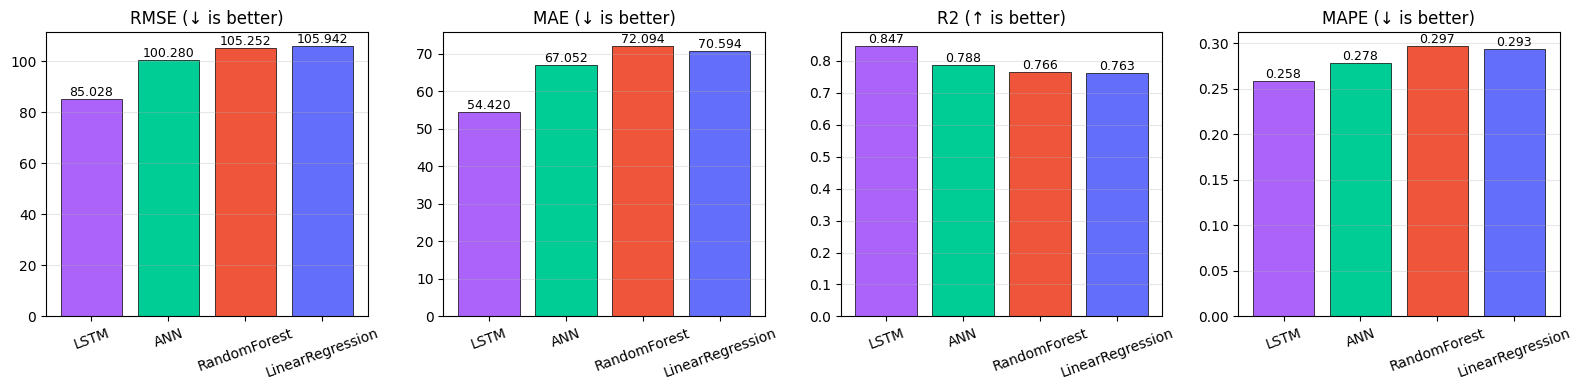

Best model (by RMSE): LSTM


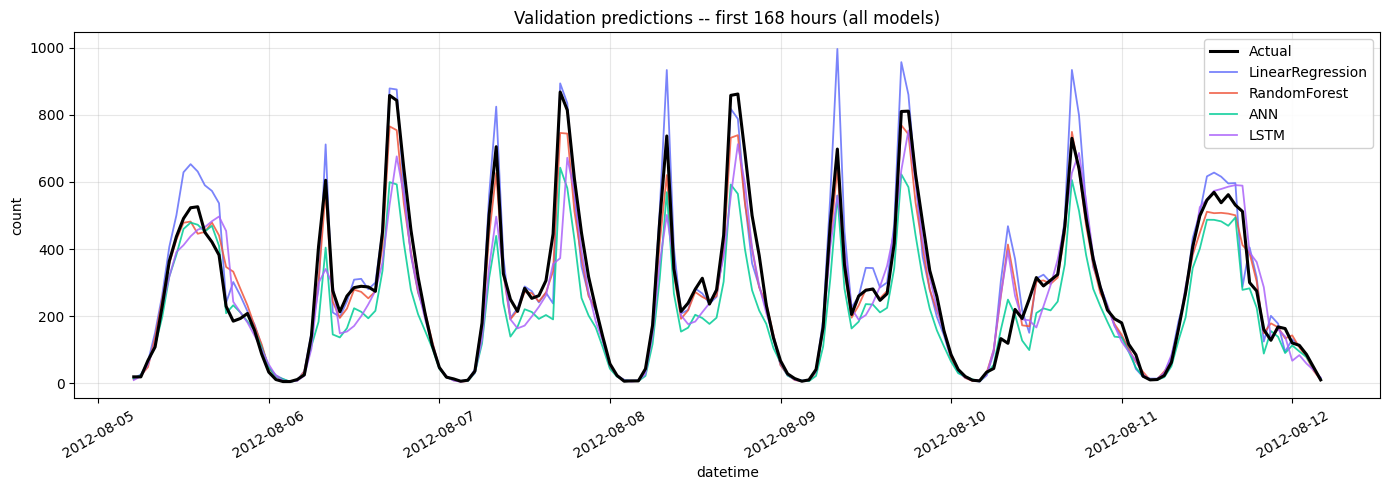

In [15]:
metrics_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(metrics_df)

# Consistent colours across all plots: one colour per model family
palette = {"LinearRegression": "#636EFA", "RandomForest": "#EF553B",
           "ANN": "#00CC96", "LSTM": "#AB63FA"}

# ---- 1) Multi-metric comparison (4 panels) ----
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
_order = metrics_df["model"].tolist()
_colors = [palette.get(m, "#888") for m in _order]
for ax, metric in zip(axes, ["RMSE", "MAE", "R2", "MAPE"]):
    vals = metrics_df[metric].tolist()
    ax.bar(_order, vals, color=_colors, edgecolor="black", linewidth=0.5)
    for i, v in enumerate(vals):
        ax.text(i, v, f"{v:.3f}", ha="center",
                va="bottom" if v >= 0 else "top", fontsize=9)
    arrow = "↓" if metric in ("RMSE", "MAE", "MAPE") else "↑"
    ax.set_title(f"{metric} ({arrow} is better)")
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

# ---- 2) Best-model selection ----
best_model_name = metrics_df.iloc[0]["model"]
print("Best model (by RMSE):", best_model_name)

# ---- 3) All models' predictions overlaid on the actual validation series ----
# The single most useful chart for a time-series task: does the model
# actually track the temporal dynamics? A scatter cannot show timing.
val_datetimes = val_outer_raw["datetime"].reset_index(drop=True)
all_preds = {
    "LinearRegression": linear_val_pred,
    "RandomForest":     rf_val_pred,
    "ANN":              ann_val_pred,
    "LSTM":             lstm_val_pred,
}

# Zoom into the first ~7 days for readability (full range would cram everything)
zoom_len = min(24 * 7, len(val_datetimes))
plt.figure(figsize=(14, 5))
plt.plot(val_datetimes[:zoom_len], y_val.to_numpy()[:zoom_len],
         color="black", linewidth=2.2, label="Actual", zorder=5)
for m_name, pred in all_preds.items():
    if len(pred) != len(val_datetimes):
        continue
    plt.plot(val_datetimes[:zoom_len], pred[:zoom_len],
             color=palette.get(m_name), linewidth=1.3, alpha=0.85,
             label=m_name)
plt.title(f"Validation predictions -- first {zoom_len} hours (all models)")
plt.xlabel("datetime"); plt.ylabel("count")
plt.legend(loc="upper right", framealpha=0.9)
plt.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.tight_layout(); plt.show()


,actual,predicted
0,19,9.478958
1,19,20.574575
2,68,56.253086
3,108,117.990219
4,229,227.165955


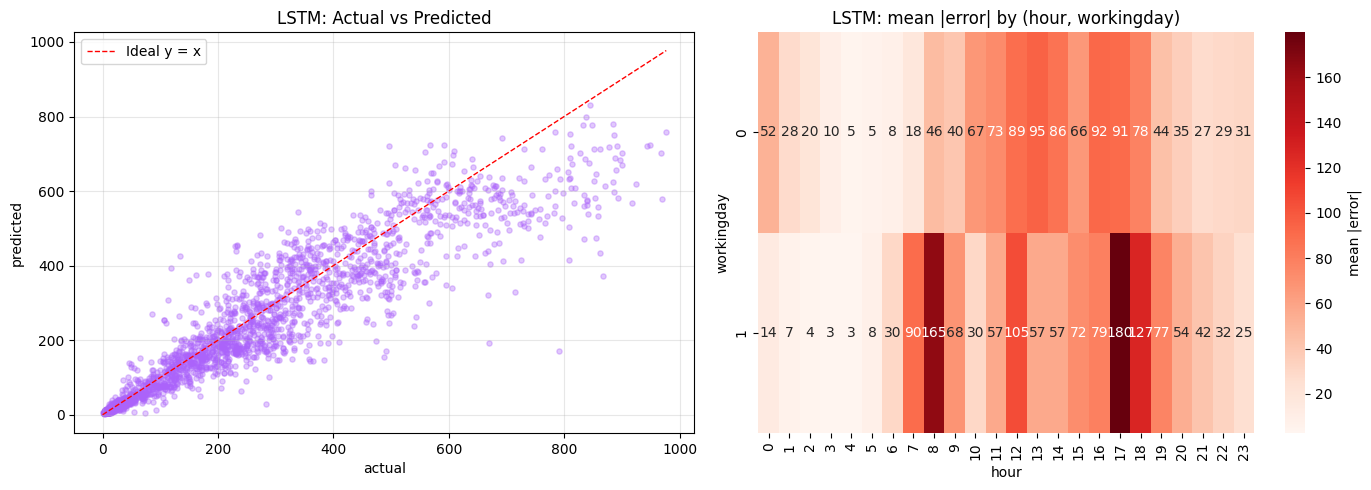

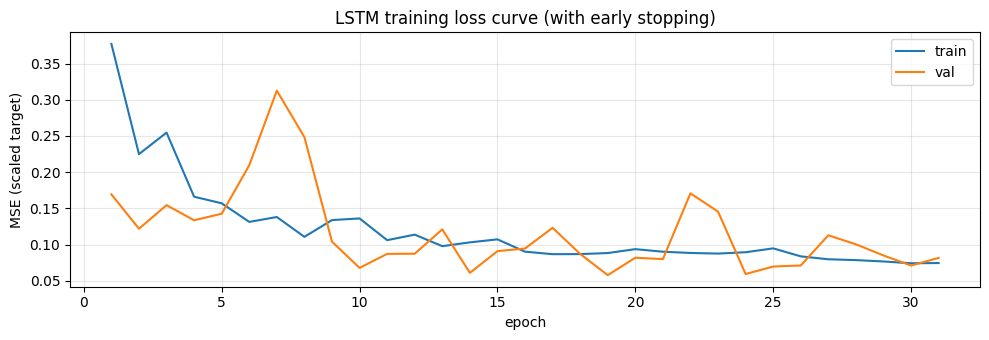


LSTM -- error by behavioural segment:


,segment,n,mae,max_err
2,workday_peak,366,117.868631,618.906662
0,weekend_holiday,715,47.443148,302.772614
1,workday_offpeak,1097,37.797915,333.044083


In [16]:
if best_model_name == "LinearRegression":
    best_val_pred = linear_val_pred
    best_val_actual = y_val.to_numpy()
elif best_model_name == "RandomForest":
    best_val_pred = rf_val_pred
    best_val_actual = y_val.to_numpy()
elif best_model_name == "ANN":
    best_val_pred = ann_val_pred
    best_val_actual = y_val.to_numpy()
else:
    best_val_pred = lstm_val_pred
    best_val_actual = lstm_val_actual

val_compare_df = pd.DataFrame({"actual": best_val_actual, "predicted": best_val_pred})
display(val_compare_df.head())

residuals = best_val_actual - best_val_pred

# ---- Two-panel diagnostic: Actual-vs-Predicted + residual heatmap ----
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Actual vs Predicted scatter
line_max = float(max(best_val_actual.max(), best_val_pred.max()))
axes[0].scatter(best_val_actual, best_val_pred, alpha=0.35, s=14,
                color=palette.get(best_model_name, "#333"))
axes[0].plot([0, line_max], [0, line_max], "r--", linewidth=1, label="Ideal y = x")
axes[0].set_xlabel("actual"); axes[0].set_ylabel("predicted")
axes[0].set_title(f"{best_model_name}: Actual vs Predicted")
axes[0].legend(loc="upper left"); axes[0].grid(alpha=0.3)

# (b) Mean absolute error by (hour, workingday): WHERE the model still fails
err_df = val_outer_raw[["datetime", "workingday"]].reset_index(drop=True).copy()
err_df["hour"] = err_df["datetime"].dt.hour
err_df["abs_error"] = np.abs(residuals)
err_pivot = err_df.pivot_table(index="workingday", columns="hour",
                               values="abs_error", aggfunc="mean")
sns.heatmap(err_pivot, cmap="Reds", annot=True, fmt=".0f",
            cbar_kws={"label": "mean |error|"}, ax=axes[1])
axes[1].set_title(f"{best_model_name}: mean |error| by (hour, workingday)")
axes[1].set_ylabel("workingday")
plt.tight_layout(); plt.show()

# ---- Training loss curves for neural models (symmetric: LSTM AND ANN) ----
if best_model_name in {"LSTM", "ANN"}:
    fig, ax = plt.subplots(figsize=(10, 3.5))
    if best_model_name == "LSTM":
        ax.plot(range(1, len(lstm_train_losses) + 1), lstm_train_losses,
                label="train", linewidth=1.5)
        ax.plot(range(1, len(lstm_val_losses) + 1), lstm_val_losses,
                label="val", linewidth=1.5)
        ax.set_title("LSTM training loss curve (with early stopping)")
    else:
        tl = ann_best_bundle["train_losses"]
        vl = ann_best_bundle["val_losses"]
        ax.plot(range(1, len(tl) + 1), tl, label="train", linewidth=1.5)
        ax.plot(range(1, len(vl) + 1), vl, label="val", linewidth=1.5)
        ax.set_title("ANN (PyTorch MLP) training loss curve (with early stopping)")
    ax.set_xlabel("epoch"); ax.set_ylabel("MSE (scaled target)")
    ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

# ---- Behavioural segment summary (compact table) ----
seg_df = err_df.copy()
seg_df["segment"] = np.where(
    (seg_df["workingday"] == 1) & (seg_df["hour"].isin([7, 8, 9, 17, 18, 19])),
    "workday_peak",
    np.where(seg_df["workingday"] == 1, "workday_offpeak", "weekend_holiday"),
)
summary = seg_df.groupby("segment").agg(
    n=("abs_error", "size"),
    mae=("abs_error", "mean"),
    max_err=("abs_error", "max"),
).reset_index().sort_values("mae", ascending=False)
print(f"\n{best_model_name} -- error by behavioural segment:")
display(summary)


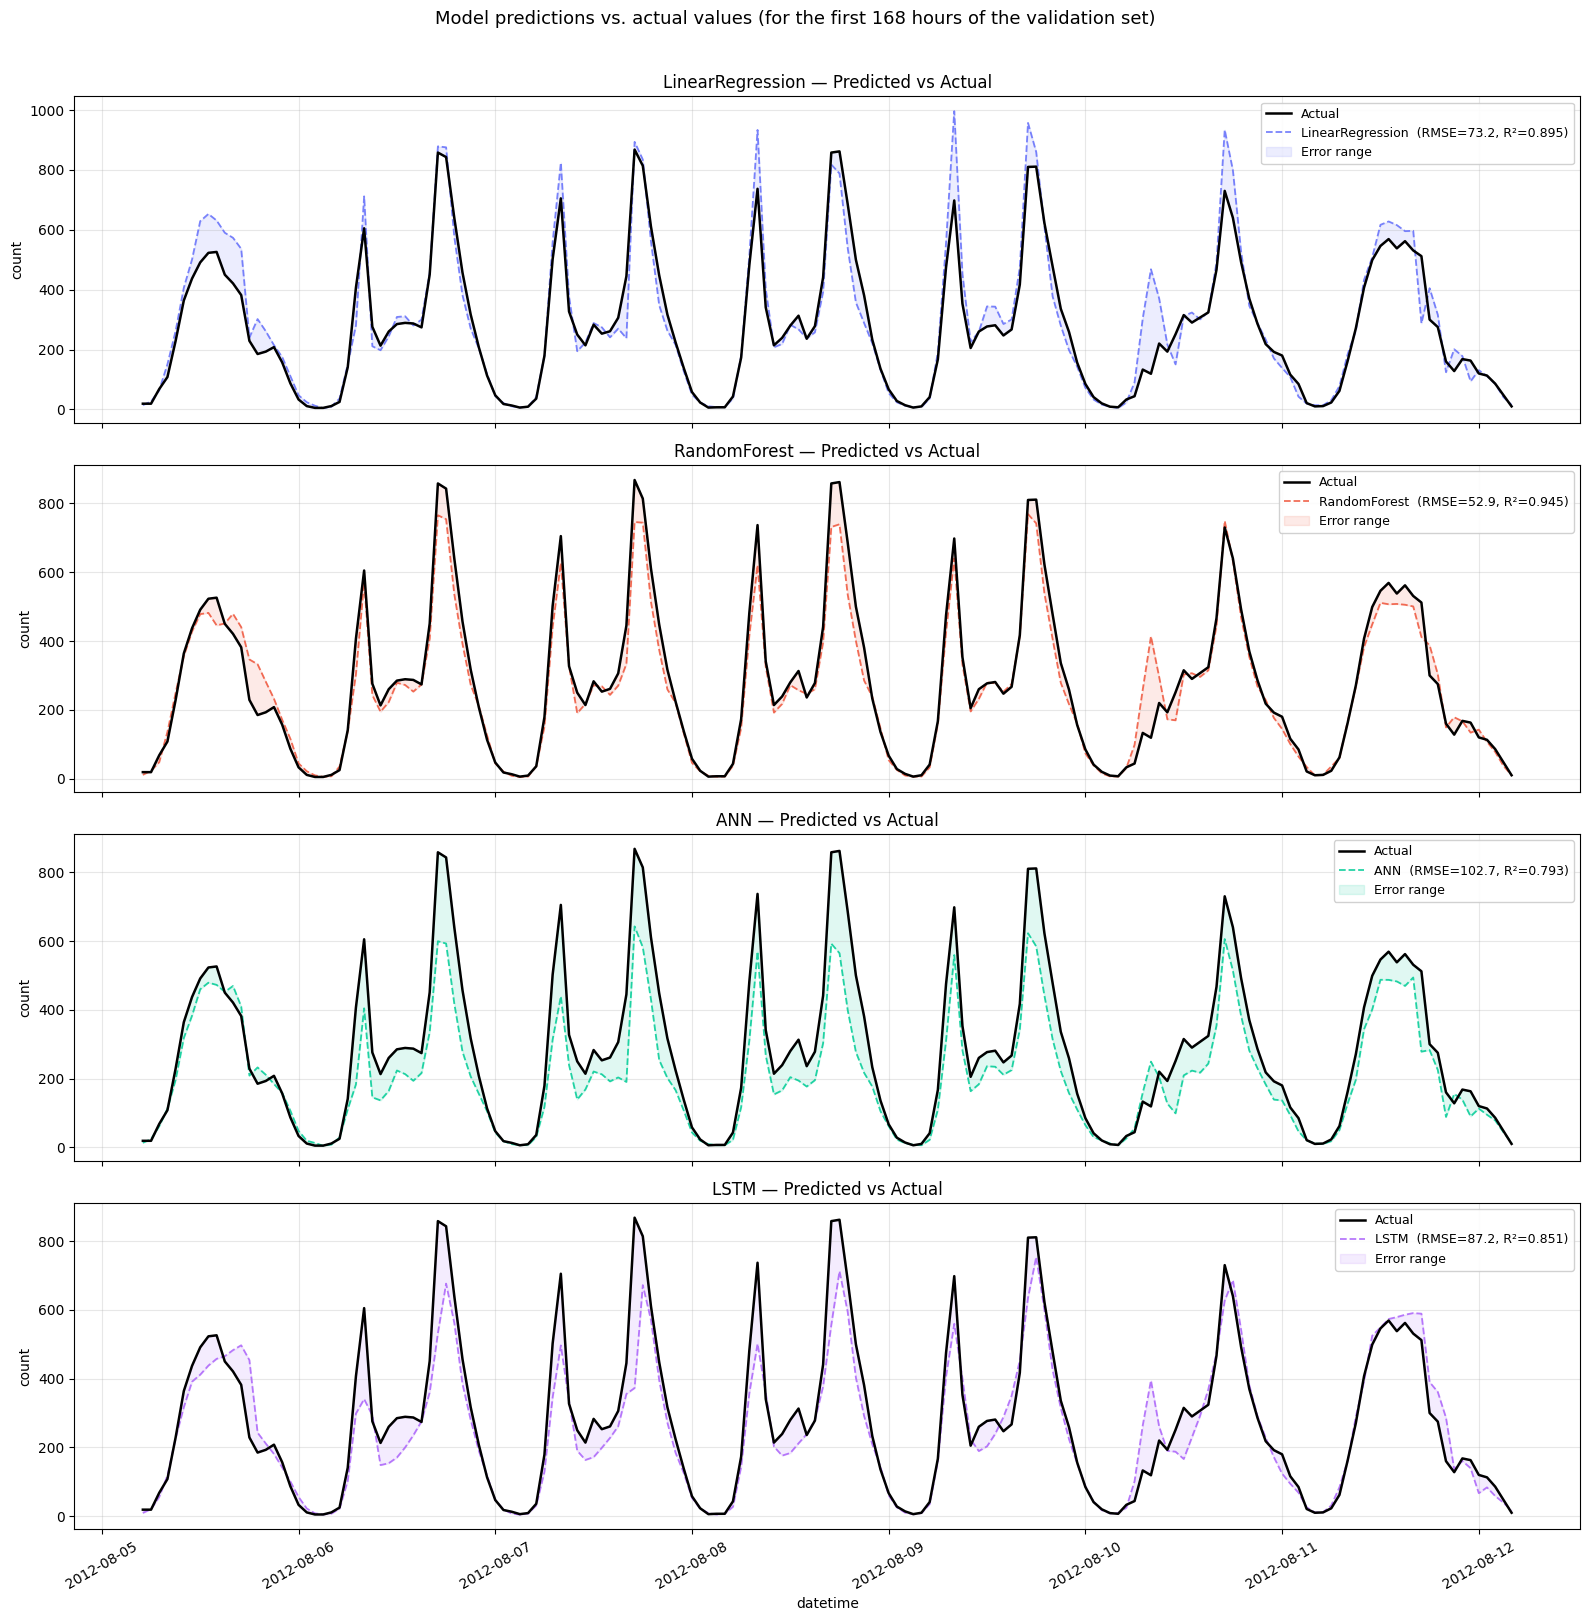

In [17]:
val_datetimes = val_outer_raw["datetime"].reset_index(drop=True)
all_preds = {
    "LinearRegression": linear_val_pred,
    "RandomForest": rf_val_pred,
    "ANN": ann_val_pred,
    "LSTM": lstm_val_pred,
}


zoom_len = min(24 * 7, len(val_datetimes))
times = val_datetimes[:zoom_len]
actual = y_val.to_numpy()[:zoom_len]

fig, axes = plt.subplots(len(all_preds), 1, figsize=(16, 4 * len(all_preds)), sharex=True)

for ax, (m_name, pred) in zip(axes, all_preds.items()):
    if len(pred) != len(val_datetimes):
        ax.set_title(f"{m_name} — Predicted length does not match; skipping")
        continue

    p = pred[:zoom_len]
    rmse = np.sqrt(mean_squared_error(actual, p))
    r2   = r2_score(actual, p)

    ax.plot(times, actual, color="black",   linewidth=1.8,
            label="Actual", zorder=5)
    ax.plot(times, p,      color=palette.get(m_name, "#888"),
            linewidth=1.3, linestyle="--", alpha=0.85,
            label=f"{m_name}  (RMSE={rmse:.1f}, R²={r2:.3f})")

    ax.fill_between(times, actual, p,
                    alpha=0.12, color=palette.get(m_name, "#888"),
                    label="Error range")

    ax.set_ylabel("count")
    ax.set_title(f"{m_name} — Predicted vs Actual")
    ax.legend(loc="upper right", framealpha=0.9, fontsize=9)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("datetime")
plt.xticks(rotation=30)
plt.suptitle(f"Model predictions vs. actual values (for the first {zoom_len} hours of the validation set)",
             fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

## Step 6b. SHAP Feature Attribution

We use SHAP (SHapley Additive exPlanations) to attribute each model prediction to its input features. SHAP is preferred over RandomForest's built-in `feature_importances_` because the latter is biased toward high-cardinality / continuous features -- including our newly added `tte_*` features, which would get an artificially high rank from that metric. SHAP values are not subject to that bias, giving a fairer validation that the new features genuinely drive predictions.


/tmp/ipykernel_3432/2337297381.py:47: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_shap, feature_names=post_names,


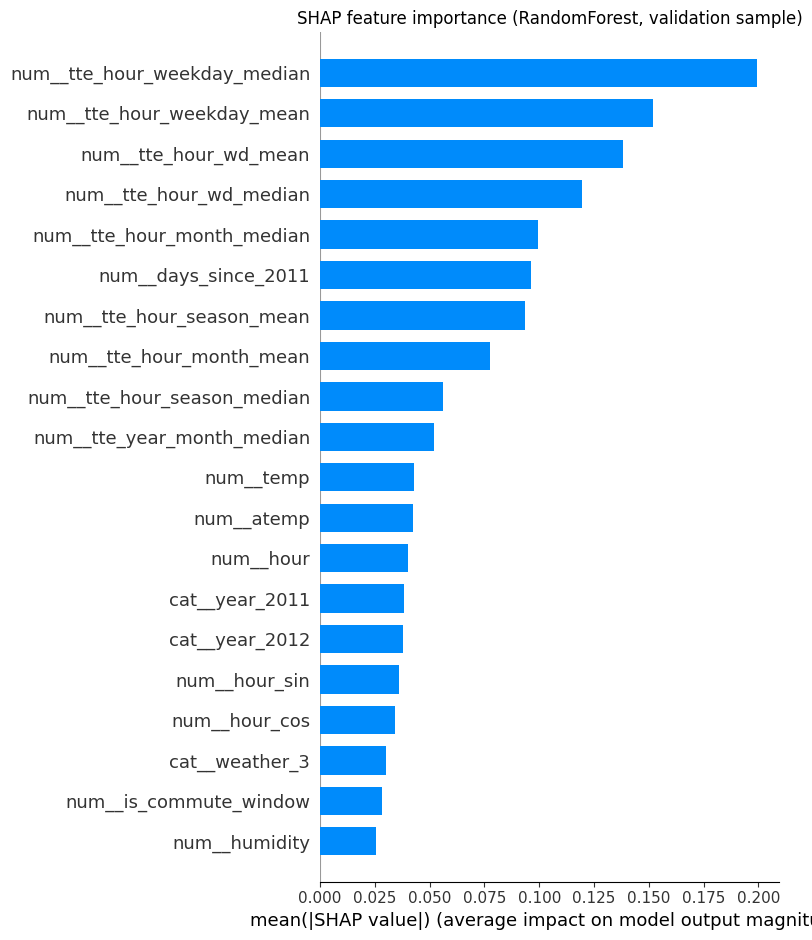

/tmp/ipykernel_3432/2337297381.py:54: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_shap, feature_names=post_names,


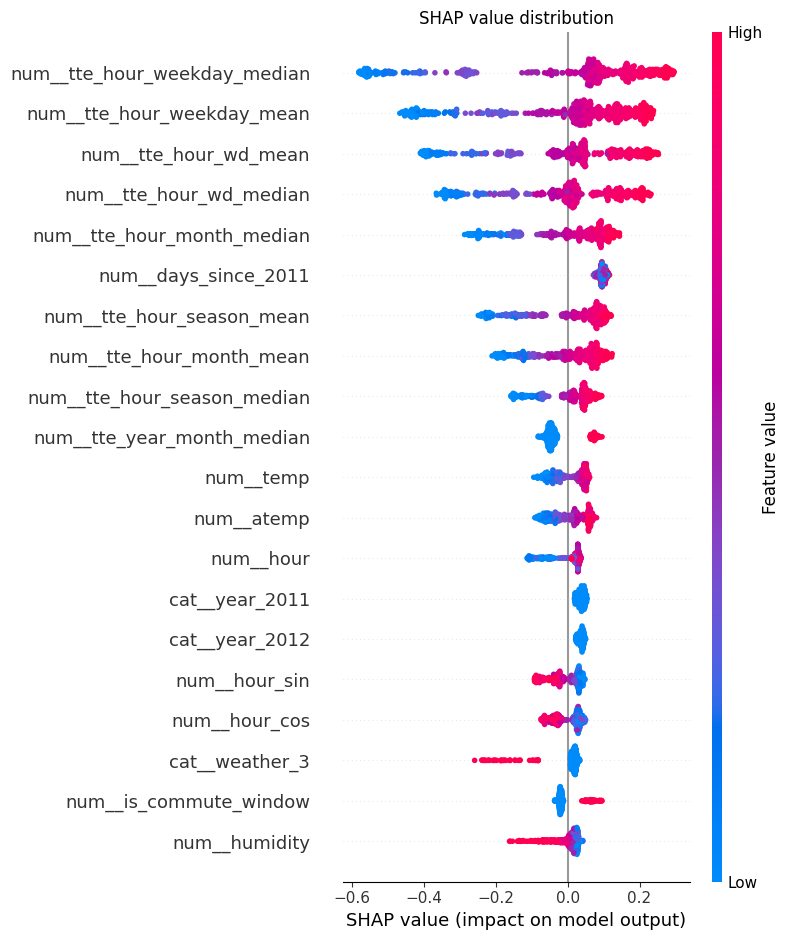

Newly added tte_* features account for 63.2% of total |SHAP|.
tte_* features appearing in top 25 by |SHAP|: 10


,feature,mean_abs_shap,is_tte
0,num__tte_hour_weekday_median,0.199588,True
1,num__tte_hour_weekday_mean,0.152086,True
2,num__tte_hour_wd_mean,0.138092,True
3,num__tte_hour_wd_median,0.119692,True
4,num__tte_hour_month_median,0.099359,True
5,num__days_since_2011,0.096209,False
6,num__tte_hour_season_mean,0.093500,True
7,num__tte_hour_month_mean,0.077621,True
8,num__tte_hour_season_median,0.056071,True
9,num__tte_year_month_median,0.052126,True


In [18]:
# ------------------------------------------------------------------
# SHAP analysis: model-agnostic feature attribution
#
# We prefer SHAP over RandomForest's built-in `feature_importances_` for two
# reasons:
#   (1) `feature_importances_` is biased toward high-cardinality / continuous
#       features -- our newly added tte_* features are continuous and would
#       get an unfair boost. SHAP values are not subject to this bias.
#   (2) SHAP gives *per-sample* attributions, letting us reason about which
#       features drive specific predictions -- useful for reporting.
#
# Fast path: TreeExplainer on the RandomForest. This runs in seconds and is
# exact (no sampling). We attribute on a random sample of the validation set
# to keep the summary plot readable.
# ------------------------------------------------------------------
try:
    import shap
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"])
    import shap

rf_fitted = trained_models["RandomForest"]
preprocessor_fitted = rf_fitted.named_steps["preprocessor"]
rf_regressor = rf_fitted.named_steps["model"]

# Transform the validation set through windspeed -> tte -> feature engineer -> preprocessor
# so SHAP explains the SAME feature space the RF sees.
X_val_preproc = rf_fitted[:-1].transform(X_val_raw)   # everything except the final RF step
try:
    post_names = preprocessor_fitted.get_feature_names_out()
except Exception:
    post_names = np.array([f"f_{i}" for i in range(X_val_preproc.shape[1])])

# Subsample for readable summary plot
rng = np.random.default_rng(RANDOM_SEED)
n_sample = min(500, X_val_preproc.shape[0])
sample_idx = rng.choice(X_val_preproc.shape[0], size=n_sample, replace=False)
X_shap = (X_val_preproc[sample_idx].toarray()
          if hasattr(X_val_preproc, "toarray") else X_val_preproc[sample_idx])

explainer = shap.TreeExplainer(rf_regressor)
shap_values = explainer.shap_values(X_shap)

# ---- Summary plot: mean |SHAP| per feature ----
fig = plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_shap, feature_names=post_names,
                  plot_type="bar", max_display=20, show=False)
plt.title("SHAP feature importance (RandomForest, validation sample)")
plt.tight_layout(); plt.show()

# ---- Beeswarm: direction and magnitude of effect ----
fig = plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_shap, feature_names=post_names,
                  max_display=20, show=False)
plt.title("SHAP value distribution")
plt.tight_layout(); plt.show()

# ---- Quantify the contribution of our new tte_* features ----
mean_abs_shap = np.abs(shap_values).mean(axis=0)
shap_df = pd.DataFrame({
    "feature": post_names,
    "mean_abs_shap": mean_abs_shap,
})
shap_df["is_tte"] = shap_df["feature"].str.contains("tte_", regex=False)
shap_df = shap_df.sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)

tte_share = shap_df.loc[shap_df["is_tte"], "mean_abs_shap"].sum() / shap_df["mean_abs_shap"].sum()
top25_tte = int(shap_df.head(25)["is_tte"].sum())
print(f"Newly added tte_* features account for {100 * tte_share:.1f}% of total |SHAP|.")
print(f"tte_* features appearing in top 25 by |SHAP|: {top25_tte}")
display(shap_df.head(15))


## Step 7. Retrain Best Model on Full Train and Predict Test

In [19]:
def predict_with_best_model(best_model_name: str) -> np.ndarray:
    if best_model_name in {"LinearRegression", "RandomForest"}:
        model = trained_models[best_model_name]
        model.fit(X_all_raw, y_all_log)
        pred = clipped_inverse(model.predict(X_test_raw))
        return np.rint(pred).astype(int)

    if best_model_name == "ANN":
        # Retrain the best ANN on FULL training data, using the tail 10%
        # (time-ordered) as the early-stopping validation slice.
        params = trained_models["ANN"]["params"]
        final_split = int(len(X_all_raw) * 0.9)
        X_final_tr = X_all_raw.iloc[:final_split].reset_index(drop=True)
        y_final_tr_log = np.log1p(y_all.iloc[:final_split].to_numpy())
        X_final_va = X_all_raw.iloc[final_split:].reset_index(drop=True)
        y_final_va_log = np.log1p(y_all.iloc[final_split:].to_numpy())

        final_bundle = train_ann_once(
            X_final_tr, y_final_tr_log,
            X_final_va, y_final_va_log,
            max_epochs=300, patience=20,
            **params,
        )
        pred = predict_ann(final_bundle, X_test_raw)
        return np.rint(pred).astype(int)

    # LSTM branch -- retrain on ALL training data with TTE features
    params = trained_models["LSTM"]["params"]

    final_windspeed_imputer = fit_windspeed_imputer(X_all_raw)
    X_all_imputed = apply_windspeed_imputer(X_all_raw, final_windspeed_imputer)
    X_test_imputed = apply_windspeed_imputer(X_test_raw, final_windspeed_imputer)

    # TTE fit on ALL training targets
    final_tte = TemporalTargetFeatures().fit(X_all_imputed, np.log1p(y_all.to_numpy()))
    X_all_tte = final_tte.transform(X_all_imputed)
    X_test_tte = final_tte.transform(X_test_imputed)

    X_all_fe = add_features(X_all_tte)[feature_cols]
    X_test_fe = add_features(X_test_tte)[feature_cols]

    preprocessor = make_preprocessor()
    X_all_scaled = np.asarray(preprocessor.fit_transform(X_all_fe), dtype=np.float32)
    X_test_scaled = np.asarray(preprocessor.transform(X_test_fe), dtype=np.float32)
    full_scaled = np.vstack([X_all_scaled, X_test_scaled])

    target_scaler = StandardScaler()
    y_scaled = target_scaler.fit_transform(np.log1p(y_all.to_numpy()).reshape(-1, 1)).ravel()

    model = BikeDemandLSTM(
        input_dim=full_scaled.shape[1],
        hidden_dim=int(params["hidden_dim"]),
        num_layers=int(params["num_layers"]),
        dropout=float(params["dropout"]),
        bidirectional=bool(params.get("bidirectional", True)),
        use_attention=bool(params.get("use_attention", True)),
    ).to(device)
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=float(params["lr"]),
        weight_decay=float(params.get("weight_decay", 0.0)),
    )
    criterion = nn.MSELoss()

    train_seq, train_targets = [], []
    for target_idx in range(params["seq_len"], len(X_all_fe)):
        train_seq.append(full_scaled[target_idx - params["seq_len"]: target_idx])
        train_targets.append(y_scaled[target_idx])

    train_ds = TensorDataset(
        torch.tensor(np.asarray(train_seq, dtype=np.float32)),
        torch.tensor(np.asarray(train_targets, dtype=np.float32)),
    )
    train_loader = DataLoader(train_ds, batch_size=int(params["batch_size"]), shuffle=False)

    for epoch in range(int(params["epochs"])):
        model.train()
        for batch_X, batch_y in train_loader:
            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(batch_X), batch_y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

    test_seq = []
    start_test_idx = len(X_all_fe)
    for target_idx in range(start_test_idx, len(full_scaled)):
        test_seq.append(full_scaled[target_idx - params["seq_len"]: target_idx])

    model.eval()
    with torch.no_grad():
        pred_scaled = model(torch.tensor(np.asarray(test_seq, dtype=np.float32)).to(device)).cpu().numpy()

    pred_log = target_scaler.inverse_transform(pred_scaled.reshape(-1, 1)).ravel()
    pred = clipped_inverse(pred_log)
    return np.rint(pred).astype(int)


final_test_pred = predict_with_best_model(best_model_name)
submission = pd.DataFrame({
    "datetime": test_raw["datetime"].dt.strftime("%Y-%m-%d %H:%M:%S"),
    "count": final_test_pred,
})
display(submission.head())


,datetime,count
0,2011-01-20 00:00:00,41
1,2011-01-20 01:00:00,9
2,2011-01-20 02:00:00,4
3,2011-01-20 03:00:00,3
4,2011-01-20 04:00:00,3


In [20]:
metrics_df.to_csv("model_metrics.csv", index=False, encoding="utf-8-sig")
val_compare_df.to_csv("best_model_validation_predictions.csv", index=False, encoding="utf-8-sig")
submission.to_csv("final_submission.csv", index=False, encoding="utf-8-sig")

with open("lstm_tuning_results.json", "w", encoding="utf-8") as f:
    json.dump(lstm_tuning_records, f, ensure_ascii=False, indent=2)

print("Saved files:")
print("model_metrics.csv")
print("best_model_validation_predictions.csv")
print("final_submission.csv")
print("lstm_tuning_results.json")


Saved files:
model_metrics.csv
best_model_validation_predictions.csv
final_submission.csv
lstm_tuning_results.json
